In [34]:
import pandas as pd
d = pd.read_csv("bdd100k_merged.csv")
d.head()

,split,image,category,traffic_light_color,occluded,truncated,x1,y1,x2,y2
0,train,bdd100k_images_100k/100k/train/0000f77c-6257be...,traffic light,green,False,False,1125.902264,133.184488,1156.978645,210.875445
1,train,bdd100k_images_100k/100k/train/0000f77c-6257be...,traffic light,green,False,False,1156.978645,136.637417,1191.507960,210.875443
2,train,bdd100k_images_100k/100k/train/0000f77c-6257be...,traffic sign,none,False,False,1101.731743,211.122087,1170.790370,233.566141
3,train,bdd100k_images_100k/100k/train/0000f77c-6257be...,traffic sign,none,False,True,0.000000,0.246631,100.381647,122.825696
4,train,bdd100k_images_100k/100k/train/0000f77c-6257be...,car,none,False,False,45.240919,254.530367,357.805838,487.906215


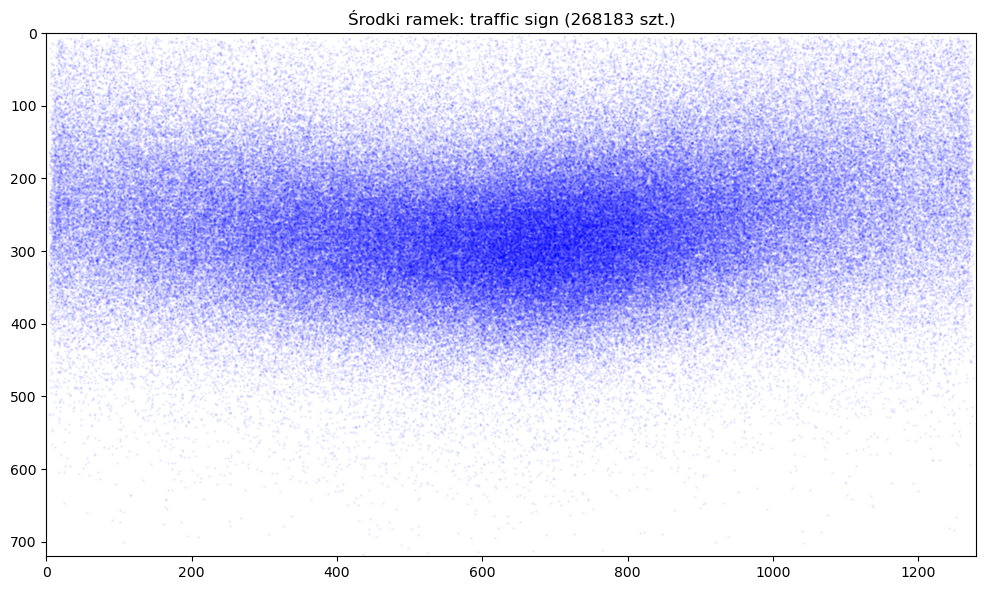

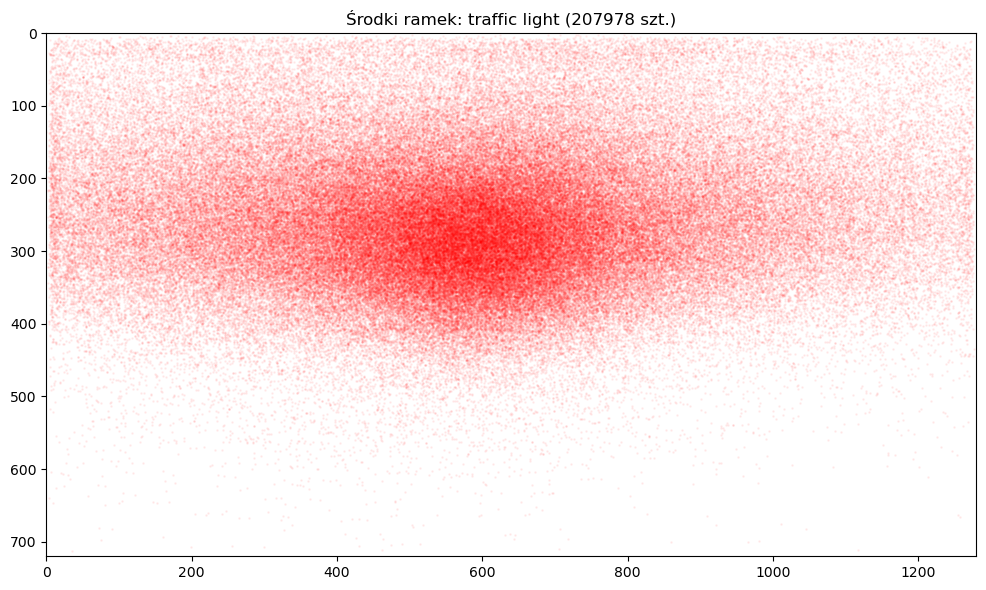

In [35]:
import matplotlib.pyplot as plt

# Rysuje środek każdej ramki danej kategorii na białym tle o rozmiarze zdjęcia (1280 x 720)
def pokaz_srodki(kategoria, kolor):
    ramki = d[d["category"] == kategoria]
    cx = (ramki["x1"] + ramki["x2"]) / 2   # środek w poziomie
    cy = (ramki["y1"] + ramki["y2"]) / 2   # środek w pionie

    plt.figure(figsize=(12, 7))
    plt.scatter(cx, cy, s=1, alpha=0.05, color=kolor)  # alpha -> im ciemniej, tym gęściej
    plt.xlim(0, 1280)
    plt.ylim(720, 0)                      # oś Y w dół, tak jak na zdjęciu
    plt.gca().set_aspect("equal")
    plt.title(f"Środki ramek: {kategoria} ({len(ramki)} szt.)")
    plt.show()

pokaz_srodki("traffic sign", "blue")
pokaz_srodki("traffic light", "red")

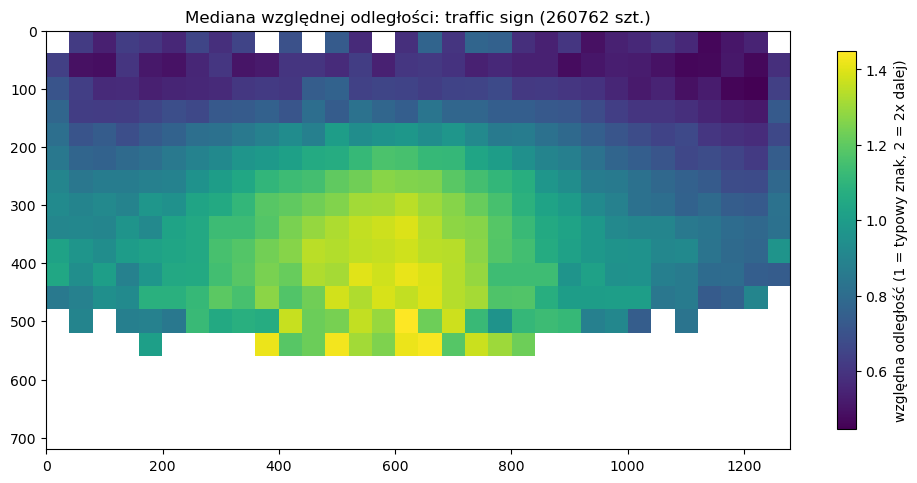

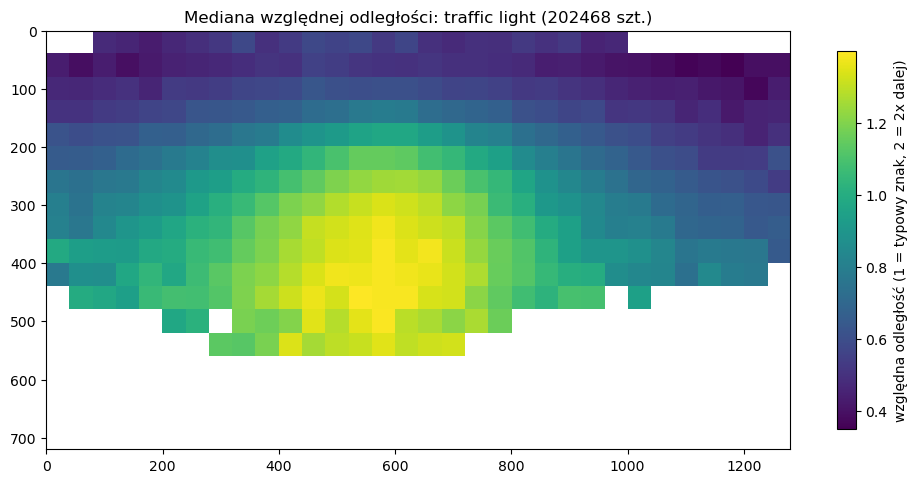

In [36]:
import numpy as np

# Nie znamy prawdziwej odległości, ale znaki mają podobny rozmiar w rzeczywistości,
# więc im mniejsza ramka na zdjęciu, tym znak jest dalej (odległość ~ 1 / rozmiar ramki).
# Względna odległość = mediana rozmiaru wszystkich znaków / rozmiar tego znaku
#   1 = typowy znak, 2 = dwa razy dalej niż typowy, 0.5 = dwa razy bliżej.

KRATKA = 40       # obraz dzielimy na kratki 40 x 40 px
MIN_ZNAKOW = 30   # kratki z mniejszą liczbą znaków pomijamy (za mało danych)

def mapa_odleglosci(kategoria):
    # pomijamy ramki ucięte przez krawędź zdjęcia - są sztucznie małe
    ramki = d[(d["category"] == kategoria) & (d["truncated"] == False)].copy()

    bok = np.sqrt((ramki["x2"] - ramki["x1"]) * (ramki["y2"] - ramki["y1"]))  # "średni bok" ramki
    ramki["odl"] = bok.median() / bok
    ramki["kol"] = ((ramki["x1"] + ramki["x2"]) / 2 // KRATKA).astype(int)     # numer kratki w poziomie
    ramki["wiersz"] = ((ramki["y1"] + ramki["y2"]) / 2 // KRATKA).astype(int)  # numer kratki w pionie

    # w każdej kratce liczymy medianę odległości znaków, których środek do niej wpada
    mapa = np.full((720 // KRATKA, 1280 // KRATKA), np.nan)
    for w in range(mapa.shape[0]):
        for k in range(mapa.shape[1]):
            w_kratce = ramki[(ramki["wiersz"] == w) & (ramki["kol"] == k)]
            if len(w_kratce) >= MIN_ZNAKOW:
                mapa[w, k] = w_kratce["odl"].median()

    plt.figure(figsize=(12, 7))
    plt.imshow(mapa, extent=[0, 1280, 720, 0], cmap="viridis")
    plt.colorbar(label="względna odległość (1 = typowy znak, 2 = 2x dalej)", shrink=0.7)
    plt.title(f"Mediana względnej odległości: {kategoria} ({len(ramki)} szt.)")
    plt.show()

mapa_odleglosci("traffic sign")
mapa_odleglosci("traffic light")

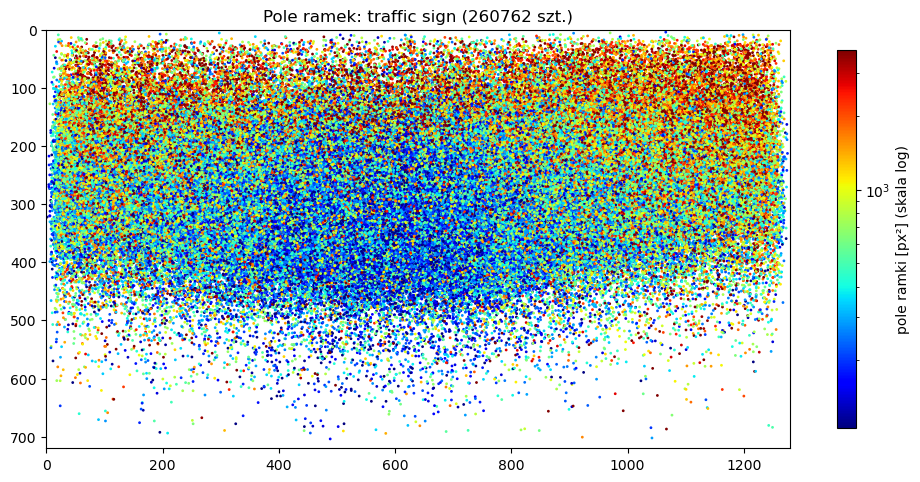

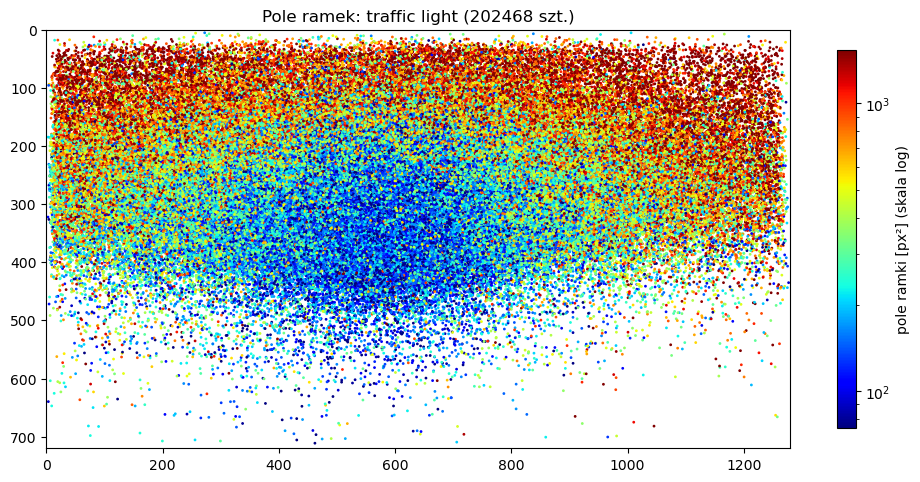

In [37]:
# Każdy znak = kropka w miejscu środka ramki, kolor kropki = pole ramki (szerokość * wysokość)
def pokaz_pola(kategoria):
    # pomijamy ramki ucięte przez krawędź zdjęcia - ich pole jest zaniżone
    ramki = d[(d["category"] == kategoria) & (d["truncated"] == False)]
    cx = (ramki["x1"] + ramki["x2"]) / 2
    cy = (ramki["y1"] + ramki["y2"]) / 2
    pole = (ramki["x2"] - ramki["x1"]) * (ramki["y2"] - ramki["y1"])

    plt.figure(figsize=(12, 7))
    # skala log, bo pola mają bardzo różne rzędy wielkości;
    # zakres kolorów 5%-95%, żeby kilka skrajnych ramek nie "spłaszczyło" kolorów
    plt.scatter(cx, cy, c=pole, s=1, cmap="jet", norm="log",
                vmin=pole.quantile(0.05), vmax=pole.quantile(0.95))
    plt.colorbar(label="pole ramki [px²] (skala log)", shrink=0.7)
    plt.xlim(0, 1280)
    plt.ylim(720, 0)   # oś Y w dół, tak jak na zdjęciu
    plt.gca().set_aspect("equal")
    plt.title(f"Pole ramek: {kategoria} ({len(ramki)} szt.)")
    plt.show()

pokaz_pola("traffic sign")
pokaz_pola("traffic light")

## Detektory klasyczne: łączenie statystyk w jedno prawdopodobieństwo

Są tu **dwa osobne modele** – jeden dla znaków, drugi dla sygnalizatorów – i każdy ma **własny test**.
Oba działają według tego samego pomysłu, więc wspólne funkcje są zdefiniowane raz, a modele różnią się tylko kandydatami i statystykami.

1. **Kandydaci** – miejsca, które *mogą* być obiektem (dla znaków: plama koloru znaku albo plama jaśniejsza niż otoczenie; dla świateł: zapalona lampa).
2. **Statystyki kandydata** – kilka prostych liczb: gdzie leży, jaki jest duży względem typowego obiektu w tym miejscu (mapa z analizy powyżej), jak wypełnia ramkę, czy stoi osobno, jak wygląda...
3. **Uczenie przez zliczanie** – na obrazach treningowych liczymy, jak często dana wartość statystyki występuje u prawdziwych obiektów, a jak często u tła.
   Iloraz tych częstości mówi, czy wartość przemawia za obiektem (> 1), czy przeciw (< 1).
4. **Łączenie** – zaczynamy od szansy „na ślepo” (ilu kandydatów w ogóle jest obiektami) i mnożymy ją przez ilorazy wszystkich statystyk.
   To jest tzw. naiwny klasyfikator Bayesa – „naiwny”, bo zakłada, że statystyki są od siebie niezależne.
5. **Ocena** – precision / recall / F1 / accuracy przy IoU ≥ 0.5 oraz sprawdzenie, która statystyka ile daje.

**Accuracy w detekcji:** zwykłe (TP + TN) / wszystko nie ma sensu, bo TN (poprawnie niewykryte tło) jest nieskończenie wiele.
Dlatego liczymy accuracy = TP / (TP + FP + FN): jaka część wszystkich wykryć i wszystkich prawdziwych obiektów to trafienia.

### Wspólne narzędzia

In [38]:
import cv2
import random

YMAX = 520   # the maps above show almost no signs or lights below this line, so we do not search there
CELL = 40    # the image is divided into 40 x 40 px cells (same grid as in the analysis above)

def iou(a, b):
    # a, b = (x1, y1, x2, y2); IoU = shared area / total area (1 = identical boxes, 0 = no overlap)
    shared = max(0, min(a[2], b[2]) - max(a[0], b[0])) * max(0, min(a[3], b[3]) - max(a[1], b[1]))
    total = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - shared
    return shared / total

def boxes_by_image(category):
    # dictionary: image path -> list of ground-truth boxes [x1, y1, x2, y2] of the given category
    rows = d[d["category"] == category]
    return {image: group[["x1", "y1", "x2", "y2"]].values.tolist() for image, group in rows.groupby("image")}

def typical_area_map(category):
    # Typical (median) box area of the category in every 40 x 40 px cell, counted on training data.
    # Same idea as the relative distance map above: objects in different places have different typical sizes.
    train = d[(d["split"] == "train") & (d["category"] == category) & (d["truncated"] == False)].copy()
    train["area"] = (train["x2"] - train["x1"]) * (train["y2"] - train["y1"])
    train["col"] = ((train["x1"] + train["x2"]) / 2 // CELL).astype(int)
    train["row"] = ((train["y1"] + train["y2"]) / 2 // CELL).astype(int)

    area_map = np.full((720 // CELL, 1280 // CELL), train["area"].median())   # default: median of all boxes
    for row in range(area_map.shape[0]):
        for col in range(area_map.shape[1]):
            in_cell = train[(train["row"] == row) & (train["col"] == col)]
            if len(in_cell) >= 30:
                area_map[row, col] = in_cell["area"].median()
    return area_map

# Images: training split for learning and tuning, validation split for the final tests
all_train = pd.Series(d[d["split"] == "train"]["image"].unique())
train_part = all_train.sample(1800, random_state=1).tolist()
train_images = train_part[:1500]   # statistics are counted on these
tune_images = train_part[1500:]    # thresholds are chosen on these
test_images = pd.Series(d[d["split"] == "val"]["image"].unique()).sample(500, random_state=1).tolist()
# 1000 more training images, used only to learn what a sign looks like (appearance model of the sign detector)
appearance_images = all_train[~all_train.isin(train_part)].sample(1000, random_state=1).tolist()

In [39]:
def collect_candidates(images, find_candidates, gt_boxes):
    # Table of all candidates found in the given images.
    # find_candidates = function that proposes candidates in one image (different for signs and for lights)
    # is_object = True if the candidate overlaps a ground-truth box (IoU >= 0.5)
    rows = []
    for image in images:
        img = cv2.imread(image)
        gt = gt_boxes.get(image, [])   # [] = no objects of this category in the image
        for c in find_candidates(img):
            box = (c["x1"], c["y1"], c["x2"], c["y2"])
            c["image"] = image
            c["is_object"] = any(iou(box, g) >= 0.5 for g in gt)
            rows.append(c)
    return pd.DataFrame(rows)

def location_statistics(cand, area_map):
    # Statistics that come from the distribution analysis: where the candidate is and how big it is
    # compared to a typical object in that place (1 = typical, 2 = twice as big).
    # Every statistic is cut into intervals, so that later we only need to count.
    w = cand["x2"] - cand["x1"]
    h = cand["y2"] - cand["y1"]
    cx = (cand["x1"] + cand["x2"]) / 2
    cy = (cand["y1"] + cand["y2"]) / 2
    typical_area = area_map[(cy // CELL).astype(int), (cx // CELL).astype(int)]   # typical area in the candidate's cell

    s = pd.DataFrame(index=cand.index)
    s["height in image (y)"] = pd.cut(cy, range(0, YMAX + 1, 40), right=False)
    s["horizontal position (x)"] = pd.cut(cx, range(0, 1281, 160), right=False)
    s["size vs typical"] = pd.cut(w * h / typical_area, [0, 0.125, 0.25, 0.5, 0.7, 1, 1.4, 2, 4, 8, 10000])
    return s

def show_candidates(image, find_candidates, gt_boxes):
    # One image: all candidates (yellow) and ground-truth boxes (green)
    img = cv2.imread(image)
    candidates = find_candidates(img)
    for c in candidates:
        cv2.rectangle(img, (int(c["x1"]), int(c["y1"])), (int(c["x2"]), int(c["y2"])), (0, 255, 255), 1)
    for g in gt_boxes[image]:
        cv2.rectangle(img, (int(g[0]), int(g[1])), (int(g[2]), int(g[3])), (0, 255, 0), 2)
    plt.figure(figsize=(16, 9))
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(f"{len(candidates)} candidates (yellow), {len(gt_boxes[image])} ground-truth boxes (green)")
    plt.axis("off")
    plt.show()

In [40]:
def train_model(stats, is_object):
    # Learning by counting. For every statistic and every interval we compute how often it occurs
    # among objects and how often among background, and keep the ratio of the two frequencies.
    # The number above the bars is that ratio: x3 = "3 times more common among objects than among background".
    ratios = {}
    n_rows = (len(stats.columns) + 3) // 4
    fig, axes = plt.subplots(n_rows, 4, figsize=(22, 4.5 * n_rows))
    for ax in axes.flatten()[len(stats.columns):]:
        ax.axis("off")   # unused plots
    for ax, name in zip(axes.flatten(), stats.columns):
        n_object = stats[name][is_object].value_counts(sort=False)          # how many objects fell into each interval
        n_background = stats[name][~is_object].value_counts(sort=False)     # how many background candidates
        # counts -> frequencies (+1 so that an empty interval does not cause division by zero)
        p_object = (n_object + 1) / (n_object + 1).sum()
        p_background = (n_background + 1) / (n_background + 1).sum()
        ratios[name] = p_object / p_background   # > 1: value more common among objects, < 1: among background

        pd.DataFrame({"objects": p_object, "background": p_background}).plot.bar(ax=ax, color=["tab:orange", "gray"], rot=45, width=0.8)
        for i in range(len(p_object)):
            ax.text(i, max(p_object.iloc[i], p_background.iloc[i]), f"×{ratios[name].iloc[i]:.1f}", ha="center", va="bottom", fontsize=8)
        ax.set_title(name)
        ax.set_xlabel("")
    plt.tight_layout()
    plt.show()

    # prior odds: how many candidates are objects compared to background, before looking at any statistic
    prior_odds = is_object.sum() / (~is_object).sum()
    print(f"prior odds: 1 object per {1 / prior_odds:.0f} background candidates")
    return {"ratios": ratios, "prior_odds": prior_odds}

def probability(model, stats, used=None):
    # odds = prior odds x ratio of every statistic, then probability = odds / (1 + odds)
    # (example: odds 1 : 3 = 0.33 give probability 0.25)
    # used = list of statistics to take into account (default: all)
    if used is None:
        used = list(model["ratios"])
    odds = pd.Series(model["prior_odds"], index=stats.index)
    for name in used:
        odds = odds * stats[name].map(model["ratios"][name]).astype(float)   # every statistic multiplies the odds by its ratio
    return odds / (1 + odds)

def explain(model, cand, stats, i, used=None):
    # Prints step by step where the probability of candidate number i comes from
    if used is None:
        used = list(model["ratios"])
    c = cand.loc[i]
    print(f"candidate {i}: box ({c['x1']:.0f}, {c['y1']:.0f}) - ({c['x2']:.0f}, {c['y2']:.0f}), really an object: {c['is_object']}")
    print(f"  {'prior odds':28s} {'':16s}   {model['prior_odds']:.4f}")
    for name in used:
        interval = stats.loc[i, name]
        print(f"  {name:28s} {str(interval):16s} × {model['ratios'][name][interval]:.2f}")
    print(f"  probability: {c['p']:.3f}\n")

In [41]:
def remove_duplicates(detections):
    # The same object is often proposed more than once (for example as a white blob and as a bright blob).
    # Going from the most probable detection, we drop every box that overlaps an already kept box (IoU >= 0.5).
    kept = []
    for image, rows in detections.groupby("image"):
        boxes = []
        for r in rows.sort_values("p", ascending=False).itertuples():
            box = (r.x1, r.y1, r.x2, r.y2)
            if all(iou(box, b) < 0.5 for b in boxes):
                boxes.append(box)
                kept.append(r.Index)
    return detections.loc[kept]

def detect(cand, threshold):
    # final detections = candidates with probability >= threshold, without duplicates
    return remove_duplicates(cand[cand["p"] >= threshold])

def match(detections, gt):
    # Pairs the detections of one image with ground-truth boxes (IoU >= 0.5), starting from the most probable detection.
    # Every ground-truth box can be used only once. Returns {detection index: number of the ground-truth box}.
    pairs = {}
    taken = [False] * len(gt)
    for r in detections.sort_values("p", ascending=False).itertuples():
        for j, g in enumerate(gt):
            if not taken[j] and iou((r.x1, r.y1, r.x2, r.y2), g) >= 0.5:
                taken[j] = True
                pairs[r.Index] = j
                break
    return pairs

def evaluate(detections, images, gt_boxes):
    TP = 0
    for image, rows in detections.groupby("image"):
        TP += len(match(rows, gt_boxes.get(image, [])))
    FP = len(detections) - TP                                            # detections that hit nothing
    FN = sum(len(gt_boxes.get(image, [])) for image in images) - TP      # objects that were not found
    precision = TP / max(1, TP + FP)   # what part of the detections are real objects
    recall = TP / max(1, TP + FN)      # what part of the real objects was detected
    f1 = 2 * precision * recall / max(1e-9, precision + recall)
    accuracy = TP / max(1, TP + FP + FN)   # there are no true negatives in detection (see the note above)
    return precision, recall, f1, accuracy

THRESHOLDS = [0.02, 0.05, 0.1, 0.15, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

def choose_threshold(cand, images, gt_boxes):
    # precision / recall / F1 / accuracy for every threshold; returns the threshold with the best F1
    table = pd.DataFrame([(t,) + evaluate(detect(cand, t), images, gt_boxes) for t in THRESHOLDS],
                         columns=["threshold", "precision", "recall", "F1", "accuracy"])
    print(table.round(3).to_string(index=False))
    return table.loc[table["F1"].idxmax(), "threshold"]

def best_f1(cand, images, gt_boxes):
    # Used to compare sets of statistics. Fixed thresholds do not fit here: with one statistic the probabilities
    # are much smaller than with ten. So the threshold keeps the 5%, 3%, 2%, 1%, 0.5% or 0.2% most probable candidates.
    thresholds = cand["p"].quantile([0.95, 0.97, 0.98, 0.99, 0.995, 0.998])
    return max(evaluate(detect(cand, t), images, gt_boxes)[2] for t in thresholds)

def contribution_table(f1_using, names, extra=[]):
    # f1_using(list of statistics) = F1 of the model that uses only these statistics.
    # "without": big drop = important statistic. "only": how good the statistic is on its own.
    # "adding": what happens when a statistic that the model does not use is added.
    f1_all = f1_using(names)
    rows = [{"statistics": "all used", "F1": f1_all, "change": 0}]
    for name in names:
        f1 = f1_using([n for n in names if n != name])
        rows.append({"statistics": "without: " + name, "F1": f1, "change": f1 - f1_all})
    for name in names:
        f1 = f1_using([name])
        rows.append({"statistics": "only: " + name, "F1": f1, "change": f1 - f1_all})
    for name in extra:
        f1 = f1_using(names + [name])
        rows.append({"statistics": "adding: " + name, "F1": f1, "change": f1 - f1_all})
    print(pd.DataFrame(rows).round(3).to_string(index=False))

def show_detections(detections, gt_boxes):
    # Four test images: green = ground truth, red = detections with colour and probability
    images = [image for image in test_images if image in gt_boxes][:4]
    plt.figure(figsize=(18, 10))
    for i, image in enumerate(images):
        img = cv2.imread(image)
        rows = detections[detections["image"] == image]
        for g in gt_boxes[image]:
            cv2.rectangle(img, (int(g[0]), int(g[1])), (int(g[2]), int(g[3])), (0, 255, 0), 2)
        for r in rows.itertuples():
            cv2.rectangle(img, (int(r.x1), int(r.y1)), (int(r.x2), int(r.y2)), (0, 0, 255), 2)
        plt.subplot(2, 2, i + 1)
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        for r in rows.itertuples():
            plt.text(r.x1, r.y1 - 5, f"{r.color} {r.p:.2f}", color="red", fontsize=9)
        plt.axis("off")
    plt.suptitle("green = ground truth, red = detections (colour and probability)")
    plt.tight_layout()
    plt.show()

## Model 1: znaki drogowe

### Paleta barw znaków

Najpierw sprawdzamy, jakie kolory faktycznie mają znaki. Każdy piksel dostaje jedną z klas: pięć **kolorów znaków**
(czerwony, żółty, zielony, niebieski, biały) albo „ciemny” / „szary”. Dla każdego prawdziwego znaku liczymy, która klasa zajmuje największą część ramki.

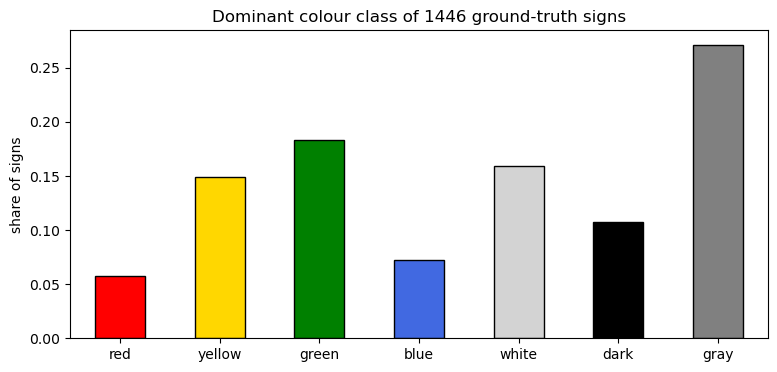

signs dominated by one of the five sign colours: 62%
signs dominated by dark or gray pixels (back of a sign, shadow, night): 38%


In [42]:
SIGN_COLORS = ["red", "yellow", "green", "blue", "white"]
PALETTE = SIGN_COLORS + ["dark", "gray"]

def palette_classes(hsv):
    # Class of every pixel: 0-4 = sign colours (in the order of SIGN_COLORS), 5 = dark, 6 = gray / other
    H, S, V = hsv[:, :, 0], hsv[:, :, 1], hsv[:, :, 2]   # hue (0-180), saturation (0-255), brightness (0-255)
    colourful = (S > 60) & (V > 40)                      # pixel clearly coloured and not too dark
    classes = np.full(H.shape, 6, np.uint8)              # default: gray / other
    classes[V <= 40] = 5                                 # dark
    classes[colourful & ((H < 10) | (H > 165))] = 0      # red
    classes[colourful & (H >= 10) & (H < 35)] = 1        # yellow
    classes[colourful & (H >= 60) & (H < 100)] = 2       # green
    classes[colourful & (H >= 100) & (H < 130)] = 3      # blue
    classes[(S < 60) & (V > 140)] = 4                    # white: little colour, a lot of brightness
    return classes

sign_boxes = boxes_by_image("traffic sign")

# Share of every palette class inside the ground-truth sign boxes (400 training images)
rows = []
for image in train_images[:400]:
    if image not in sign_boxes:
        continue
    classes = palette_classes(cv2.cvtColor(cv2.imread(image), cv2.COLOR_BGR2HSV))
    for x1, y1, x2, y2 in sign_boxes[image]:
        inside = classes[int(y1):int(y2) + 1, int(x1):int(x2) + 1]
        rows.append(np.bincount(inside.ravel(), minlength=7) / inside.size)
shares = pd.DataFrame(rows, columns=PALETTE)
dominant = shares.idxmax(axis=1).value_counts(normalize=True).reindex(PALETTE)   # which class covers most of the box

dominant.plot.bar(color=["red", "gold", "green", "royalblue", "lightgray", "black", "gray"], edgecolor="black", rot=0, figsize=(9, 4))
plt.title(f"Dominant colour class of {len(shares)} ground-truth signs")
plt.ylabel("share of signs")
plt.show()
print(f"signs dominated by one of the five sign colours: {dominant[SIGN_COLORS].sum():.0%}")
print(f"signs dominated by dark or gray pixels (back of a sign, shadow, night): {dominant[['dark', 'gray']].sum():.0%}")

### Kandydaci

Ok. 60% znaków ma wyraźny kolor z palety, ale reszta jest w większości szara lub ciemna (tył znaku, cień, noc).
Dlatego kandydaci pochodzą z dwóch źródeł:

- **plamy koloru** – spójna plama jednego z pięciu kolorów znaków,
- **plamy jaśniejsze niż otoczenie** (kontrast) – piksel jest „jasny”, jeśli jest jaśniejszy od średniej ze swojego otoczenia 31 × 31 px.
  Łapie to znaki, które nie mają nasyconego koloru, ale odcinają się od tła.

Dla każdej plamy bierzemy jej **zewnętrzny obrys**. Dzięki temu napis lub symbol w środku znaku nie psuje kształtu:
wypełnienie ramki liczymy z pola obrysu (prostokąt ≈ 1, koło ≈ 0.8, romb ≈ 0.5).

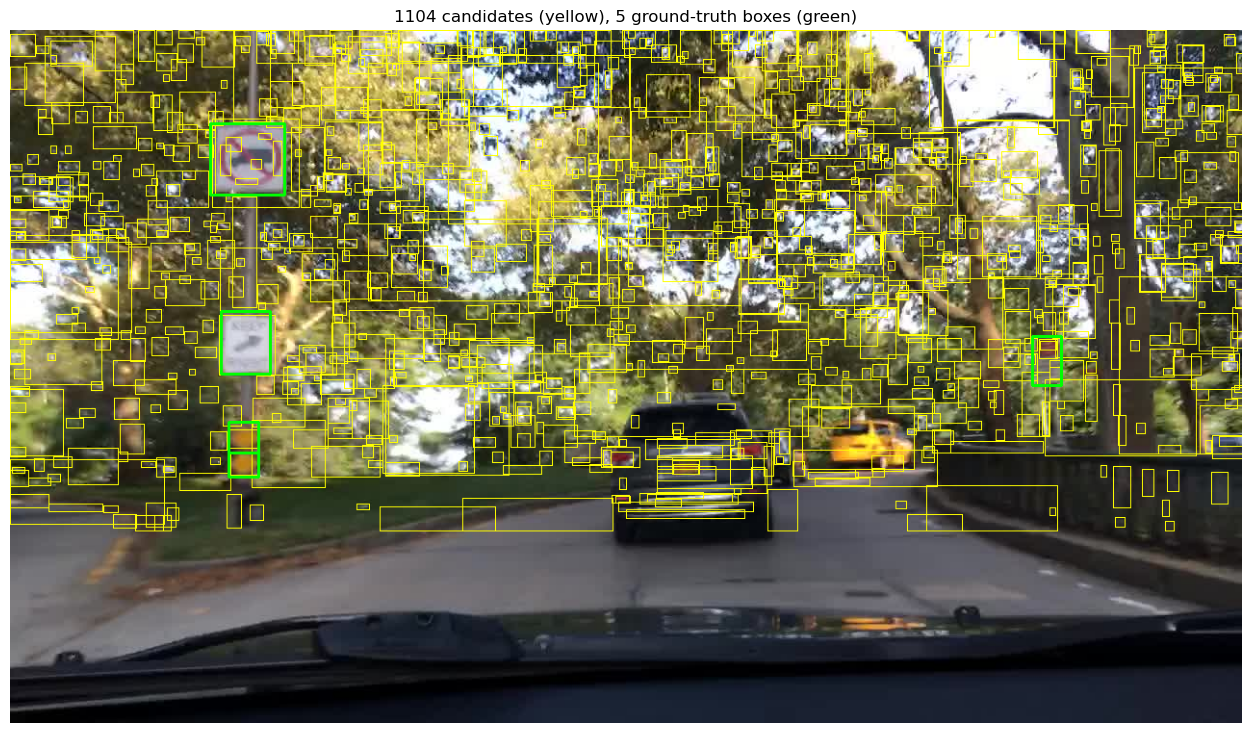

In [43]:
def sign_candidates(img):
    # Candidate = blob of a sign colour or blob brighter than its surroundings.
    # Returns a list of dictionaries (one dictionary = one candidate).
    top = img[:YMAX]
    hsv = cv2.cvtColor(top, cv2.COLOR_BGR2HSV)
    S, V = hsv[:, :, 1], hsv[:, :, 2]
    classes = palette_classes(hsv)

    masks = {color: classes == i for i, color in enumerate(SIGN_COLORS)}   # one True / False mask per sign colour
    # bright = pixel brighter by more than 8 than the mean of its 31 x 31 neighbourhood
    masks["bright"] = cv2.adaptiveThreshold(V, 1, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, 31, -8) > 0

    candidates = []
    for color, mask in masks.items():
        mask = mask.astype(np.uint8)
        outlines, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)   # outer outline of every blob
        for outline in outlines:
            x, y, w, h = cv2.boundingRect(outline)
            if w < 6 or h < 6 or w > 300 or h > 300:   # too small or too big for a sign
                continue
            # ring around the box (half a box wide) and the inside of the box
            ya, yb, xa, xb = max(0, y - h // 2), y + h + h // 2, max(0, x - w // 2), x + w + w // 2
            ring_size = mask[ya:yb, xa:xb].size - w * h
            mask_around = int(mask[ya:yb, xa:xb].sum()) - int(mask[y:y + h, x:x + w].sum())
            brightness_inside = int(V[y:y + h, x:x + w].sum())
            brightness_around = int(V[ya:yb, xa:xb].sum()) - brightness_inside

            # palette inside the box: share of every colour class
            shares = np.bincount(classes[y:y + h, x:x + w].ravel(), minlength=7) / (w * h)
            dominant = PALETTE[shares.argmax()]
            if dominant in ("red", "green", "blue"):
                text = shares[4]     # text on these signs is white
            elif dominant in ("white", "yellow"):
                text = shares[5]     # text on these signs is dark
            else:
                text = -1            # the box has no sign colour

            candidates.append({
                "x1": x, "y1": y, "x2": x + w, "y2": y + h,
                "color": color,                                               # which mask the blob comes from
                "fill": cv2.contourArea(outline) / ((w - 1) * (h - 1)),       # area inside the outline / area of the box
                "same_around": mask_around / ring_size,                       # 0 = the blob stands alone
                "saturation": S[y:y + h, x:x + w].mean(),                     # mean "colourfulness" of the box
                "contrast": brightness_inside / (w * h) - brightness_around / ring_size,   # > 0: brighter than surroundings
                "palette_share": shares[:5].sum(),                            # part of the box in sign colours
                "text": text,                                                 # part of the box in the colour of text
            })
    return candidates

show_candidates("bdd100k_images_100k/100k/train/002d290d-fa2a8964.jpg", sign_candidates, sign_boxes)

### Statystyka „wygląd” (pomysł z `lab2A_detekcja.ipynb`)

Dotychczasowe statystyki nie patrzą, **co jest w środku** ramki – okno i znak o tym samym kolorze i rozmiarze wyglądają dla nich tak samo.
Z zespołowego notatnika bierzemy to, co tam działało najlepiej: opis wycinka cechami **HOG** (histogram kierunków krawędzi)
i histogramem barwy oraz klasyfikator **gradient boosting**, który odpowiada na pytanie „czy ten wycinek wygląda jak znak?”.

Jego odpowiedź (liczba od 0 do 1) traktujemy jak **jeszcze jedną statystykę** – tniemy ją na przedziały i zliczamy tak samo jak pozostałe.
Klasyfikator wyglądu uczymy na **innych obrazach** niż te, na których zliczamy statystyki, żeby jego oceny były uczciwe (na obrazach, które już widział, byłyby zawyżone).

In [44]:
from sklearn.ensemble import HistGradientBoostingClassifier

# HOG: 32 x 32 patch, blocks 16 x 16 moved by 8, cells 8 x 8, 9 edge directions -> 324 numbers
HOG = cv2.HOGDescriptor((32, 32), (16, 16), (8, 8), (8, 8), 9)

def appearance_features(gray, hsv, box):
    # Describes how the inside of the box looks:
    # 1) HOG - which edge directions occur in which part of the patch (outline of the sign, symbols inside)
    # 2) hue histogram - which colours occur (weighted by saturation and brightness) + mean saturation and brightness
    x1, y1, x2, y2 = box
    mx, my = 0.1 * (x2 - x1), 0.1 * (y2 - y1)   # 10% margin, so that the edge of the sign is visible
    xa, ya = int(max(0, x1 - mx)), int(max(0, y1 - my))
    xb, yb = int(np.ceil(x2 + mx)), int(np.ceil(y2 + my))

    patch = cv2.resize(gray[ya:yb, xa:xb], (32, 32), interpolation=cv2.INTER_AREA)
    hog = HOG.compute(cv2.equalizeHist(patch)).ravel()   # equalizeHist: the same contrast by day and by night

    small = cv2.resize(hsv[ya:yb, xa:xb], (8, 8), interpolation=cv2.INTER_AREA).reshape(-1, 3).astype(float)
    hue, saturation, brightness = small[:, 0], small[:, 1], small[:, 2]
    hue_histogram = np.bincount((hue // 15).astype(int), weights=saturation * brightness / 255 ** 2, minlength=12) / 64
    return np.concatenate([hog, hue_histogram, [saturation.mean() / 255, brightness.mean() / 255]])

def appearance_training_set(images, negatives_per_image=40):
    # Patches for learning what a sign looks like.
    # Positive: ground-truth sign boxes and candidates that hit a sign. Negative: random candidates far from any sign.
    random.seed(0)
    X, y = [], []
    for image in images:
        img = cv2.imread(image)
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
        gt = sign_boxes.get(image, [])
        positives = [g for g in gt if g[2] - g[0] >= 6 and g[3] - g[1] >= 6]
        negatives = []
        for c in sign_candidates(img):
            box = (c["x1"], c["y1"], c["x2"], c["y2"])
            best_iou = max([iou(box, g) for g in gt], default=0)
            if best_iou >= 0.5:
                positives.append(box)
            elif best_iou < 0.3:
                negatives.append(box)
        negatives = random.sample(negatives, min(negatives_per_image, len(negatives)))
        for box in positives:
            X.append(appearance_features(gray, hsv, box))
            y.append(1)
        for box in negatives:
            X.append(appearance_features(gray, hsv, box))
            y.append(0)
    return np.array(X, dtype=np.float32), np.array(y)

# about 3 min
X, y = appearance_training_set(appearance_images)
print("patches:", len(y), " of which signs:", y.sum())

# Gradient boosting = many small decision trees, each one corrects the mistakes of the previous ones.
# class_weight="balanced": signs are rare, so their mistakes count more.
appearance_model = HistGradientBoostingClassifier(max_iter=200, class_weight="balanced", random_state=0).fit(X, y)

def scored_sign_candidates(img):
    # sign candidates + appearance score of every candidate (0 = looks like background, 1 = looks like a sign)
    candidates = sign_candidates(img)
    if len(candidates) == 0:
        return []
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    X = np.array([appearance_features(gray, hsv, (c["x1"], c["y1"], c["x2"], c["y2"])) for c in candidates], dtype=np.float32)
    scores = appearance_model.predict_proba(X)[:, 1]
    for c, score in zip(candidates, scores):
        c["appearance"] = score
    return candidates

AttributeError: module 'cv2' has no attribute 'HOGDescriptor'

In [ ]:
# Candidates from all images, with the appearance score (about 5 min)
sign_train = collect_candidates(train_images, scored_sign_candidates, sign_boxes)
sign_tune = collect_candidates(tune_images, scored_sign_candidates, sign_boxes)
sign_test = collect_candidates(test_images, scored_sign_candidates, sign_boxes)

print("training candidates:", len(sign_train), " of which hit a sign:", sign_train["is_object"].sum())
sign_train.head()

training candidates: 686501  of which hit a sign: 3292


,x1,y1,x2,y2,color,fill,same_around,saturation,contrast,palette_share,text,appearance,image,is_object
0,1025,500,1039,508,red,0.137363,0.000000,110.982143,-9.880952,0.517857,-1.000000,0.005690,bdd100k_images_100k/100k/train/115d9e12-16ebd2...,False
1,402,499,414,506,red,0.219697,0.043860,138.452381,6.368421,0.678571,0.023810,0.055258,bdd100k_images_100k/100k/train/115d9e12-16ebd2...,False
2,816,495,834,520,red,0.348039,0.216553,68.080000,9.788209,0.482222,-1.000000,0.212158,bdd100k_images_100k/100k/train/115d9e12-16ebd2...,False
3,871,486,877,496,red,0.555556,0.000000,110.216667,-16.511111,1.000000,0.000000,0.001022,bdd100k_images_100k/100k/train/115d9e12-16ebd2...,False
4,833,486,841,502,red,0.028571,0.083333,114.234375,-15.250000,0.601562,0.398438,0.011901,bdd100k_images_100k/100k/train/115d9e12-16ebd2...,False


### Statystyki i uczenie przez zliczanie

Pomarańczowe słupki – jak często dany przedział występuje u znaków, szare – u tła. Liczba nad słupkami to iloraz.
Statystyka jest tym lepsza, im bardziej jej ilorazy różnią się od 1.

Trzy ostatnie statystyki (tekst w środku, kontrast z otoczeniem, udział palety) są policzone i pokazane, ale **model ich nie używa** –
tabela w dalszej części pokazuje, że po dodaniu nie poprawiają wyniku.

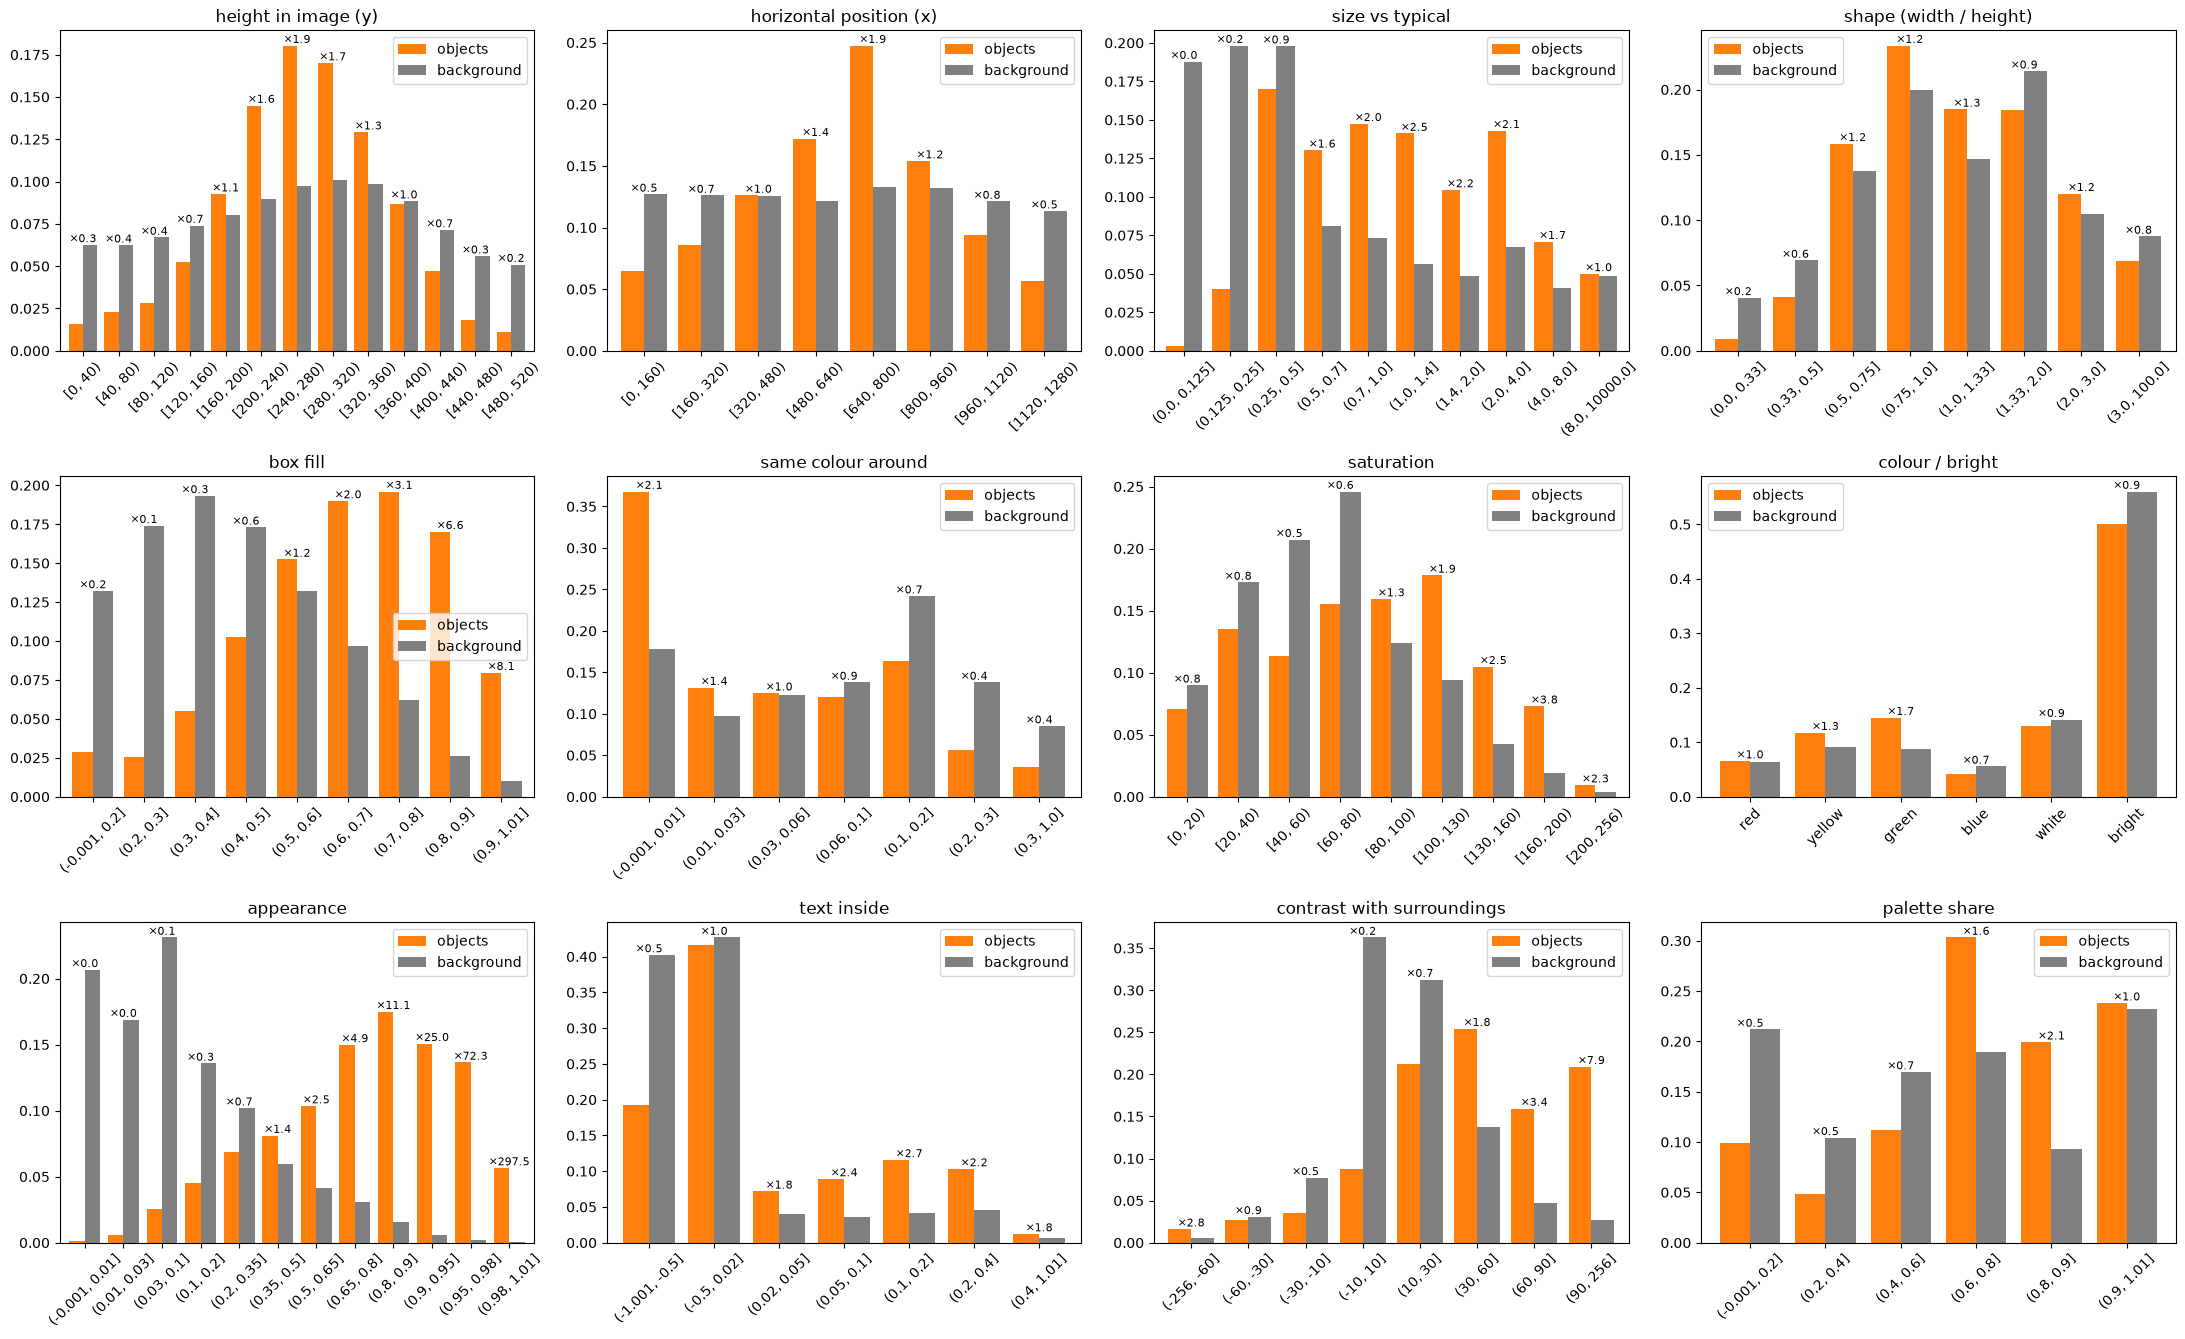

prior odds: 1 object per 208 background candidates


In [ ]:
sign_area_map = typical_area_map("traffic sign")

def sign_statistics(cand):
    w = cand["x2"] - cand["x1"]
    h = cand["y2"] - cand["y1"]
    s = location_statistics(cand, sign_area_map)   # position and size vs typical
    s["shape (width / height)"] = pd.cut(w / h, [0, 0.33, 0.5, 0.75, 1, 1.33, 2, 3, 100])
    s["box fill"] = pd.cut(cand["fill"], [0, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.01], include_lowest=True)
    s["same colour around"] = pd.cut(cand["same_around"], [0, 0.01, 0.03, 0.06, 0.1, 0.2, 0.3, 1], include_lowest=True)
    s["saturation"] = pd.cut(cand["saturation"], [0, 20, 40, 60, 80, 100, 130, 160, 200, 256], right=False)
    s["colour / bright"] = pd.Categorical(cand["color"], categories=SIGN_COLORS + ["bright"])
    s["appearance"] = pd.cut(cand["appearance"], [0, 0.01, 0.03, 0.1, 0.2, 0.35, 0.5, 0.65, 0.8, 0.9, 0.95, 0.98, 1.01], include_lowest=True)
    # tested, but not used by the model:
    s["text inside"] = pd.cut(cand["text"], [-1, -0.5, 0.02, 0.05, 0.1, 0.2, 0.4, 1.01], include_lowest=True)   # first interval = no sign colour
    s["contrast with surroundings"] = pd.cut(cand["contrast"], [-256, -60, -30, -10, 10, 30, 60, 90, 256])
    s["palette share"] = pd.cut(cand["palette_share"], [0, 0.2, 0.4, 0.6, 0.8, 0.9, 1.01], include_lowest=True)
    return s

SIGN_EXTRA = ["text inside", "contrast with surroundings", "palette share"]   # statistics that are only tested

sign_train_stats = sign_statistics(sign_train)
sign_model = train_model(sign_train_stats, sign_train["is_object"])
SIGN_USED = [name for name in sign_model["ratios"] if name not in SIGN_EXTRA]   # statistics used by the model

### Prawdopodobieństwo i wybór progu

`explain` wypisuje dla jednego kandydata, która statystyka o ile zmieniła szansę. Próg wybieramy na obrazach do strojenia (najlepsze F1).

In [ ]:
sign_tune_stats = sign_statistics(sign_tune)
sign_test_stats = sign_statistics(sign_test)
sign_tune["p"] = probability(sign_model, sign_tune_stats, SIGN_USED)
sign_test["p"] = probability(sign_model, sign_test_stats, SIGN_USED)

explain(sign_model, sign_tune, sign_tune_stats, sign_tune["p"].idxmax(), SIGN_USED)   # the most probable candidate
explain(sign_model, sign_tune, sign_tune_stats, sign_tune["p"].idxmin(), SIGN_USED)   # the least probable candidate

SIGN_THRESHOLD = choose_threshold(sign_tune, tune_images, sign_boxes)
print("\nchosen threshold:", SIGN_THRESHOLD)

candidate 84557: box (692, 145) - (783, 163), really an object: True
  prior odds                                      0.0048
  height in image (y)          [120, 160)       × 0.71
  horizontal position (x)      [640, 800)       × 1.86
  size vs typical              (2.0, 4.0]       × 2.13
  shape (width / height)       (3.0, 100.0]     × 0.78
  box fill                     (0.8, 0.9]       × 6.58
  same colour around           (-0.001, 0.01]   × 2.07
  saturation                   [130, 160)       × 2.47
  colour / bright              green            × 1.65
  appearance                   (0.98, 1.01]     × 297.45
  probability: 0.994

candidate 61042: box (81, 101) - (87, 124), really an object: False
  prior odds                                      0.0048
  height in image (y)          [80, 120)        × 0.42
  horizontal position (x)      [0, 160)         × 0.51
  size vs typical              (0.0, 0.125]     × 0.02
  shape (width / height)       (0.0, 0.33]      × 0.22
  box fill

 threshold  precision  recall    F1  accuracy
      0.02      0.057   0.389 0.100     0.052
      0.05      0.088   0.350 0.141     0.076
      0.10      0.122   0.308 0.175     0.096
      0.15      0.148   0.279 0.193     0.107
      0.20      0.170   0.266 0.208     0.116
      0.30      0.213   0.231 0.221     0.125
      0.40      0.257   0.208 0.230     0.130
      0.50      0.296   0.179 0.223     0.126
      0.60      0.344   0.152 0.211     0.118
      0.70      0.392   0.123 0.188     0.104
      0.80      0.452   0.097 0.159     0.087
      0.90      0.579   0.062 0.112     0.059

chosen threshold: 0.4


### Która statystyka ile daje?

Wyłączamy po jednej statystyce („without”), zostawiamy tylko jedną („only”) albo dodajemy jedną z nieużywanych („adding”)
i patrzymy na F1 na obrazach do strojenia. Różnice rzędu ±0.01 to szum (obrazów do strojenia jest tylko 300).

In [ ]:
def sign_f1_using(names):
    sign_tune["p"] = probability(sign_model, sign_tune_stats, names)
    return best_f1(sign_tune, tune_images, sign_boxes)

contribution_table(sign_f1_using, SIGN_USED, SIGN_EXTRA)
sign_tune["p"] = probability(sign_model, sign_tune_stats, SIGN_USED)   # restore the probability of the model

                        statistics    F1  change
                          all used 0.222   0.000
      without: height in image (y) 0.220  -0.002
  without: horizontal position (x) 0.221  -0.001
          without: size vs typical 0.209  -0.013
   without: shape (width / height) 0.222   0.000
                 without: box fill 0.208  -0.014
       without: same colour around 0.210  -0.012
               without: saturation 0.231   0.009
          without: colour / bright 0.224   0.003
               without: appearance 0.117  -0.105
         only: height in image (y) 0.013  -0.209
     only: horizontal position (x) 0.013  -0.209
             only: size vs typical 0.021  -0.201
      only: shape (width / height) 0.010  -0.211
                    only: box fill 0.052  -0.169
          only: same colour around 0.021  -0.201
                  only: saturation 0.023  -0.199
             only: colour / bright 0.014  -0.208
                  only: appearance 0.177  -0.044
               addin

### Test 1: znaki drogowe

Obrazy z `val` – nie były używane ani do uczenia wyglądu, ani do zliczania statystyk, ani do wyboru progu.
„Recall ceiling” to recall wszystkich kandydatów, czyli górna granica: znaku, który nie ma swojego kandydata, nie da się już wykryć.

TEST 1 - traffic signs (500 images, threshold 0.4):
precision = 0.214  recall = 0.175  F1 = 0.192  accuracy = 0.106


recall ceiling (all candidates): 0.449


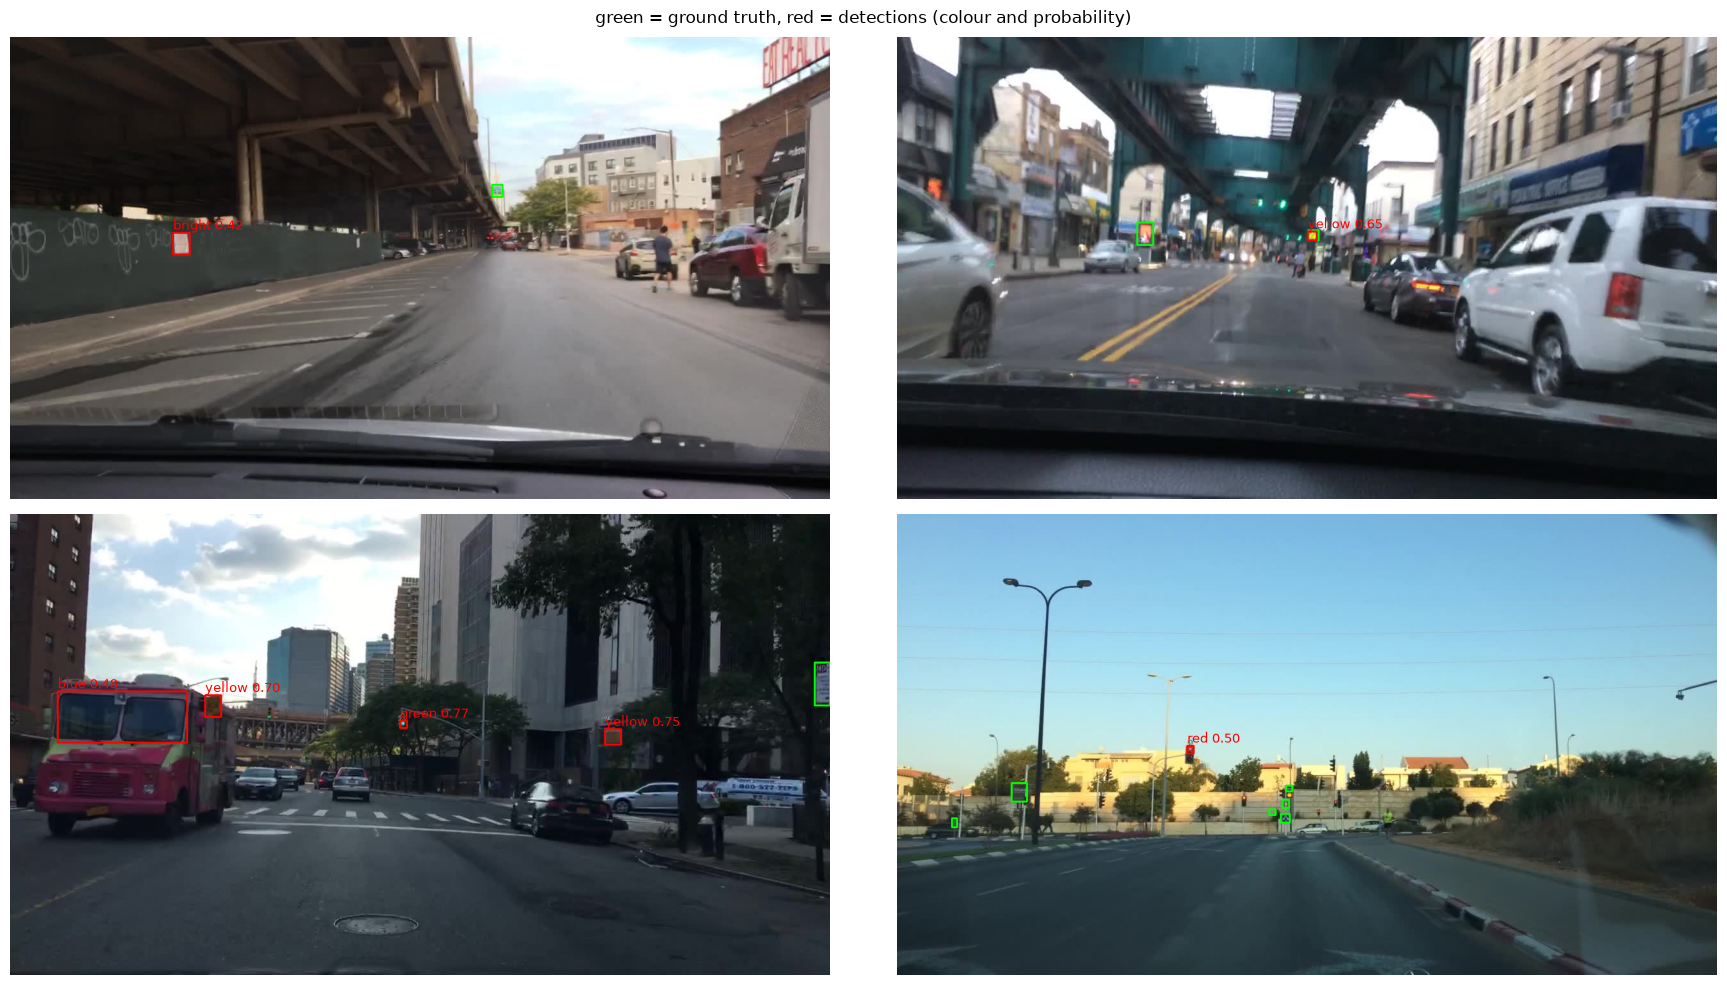

In [ ]:
sign_detections = detect(sign_test, SIGN_THRESHOLD)
precision, recall, f1, accuracy = evaluate(sign_detections, test_images, sign_boxes)
print(f"TEST 1 - traffic signs ({len(test_images)} images, threshold {SIGN_THRESHOLD}):")
print(f"precision = {precision:.3f}  recall = {recall:.3f}  F1 = {f1:.3f}  accuracy = {accuracy:.3f}")
print(f"recall ceiling (all candidates): {evaluate(sign_test, test_images, sign_boxes)[1]:.3f}")

show_detections(sign_detections, sign_boxes)

## Model 2: sygnalizatory

Zaczynamy od **zapalonej lampy**: małej, jasnej, mocno nasyconej plamy w kolorze czerwonym, żółtym lub zielonym.
Kolor lampy jest od razu przewidywanym kolorem światła.

Ramka w adnotacjach obejmuje jednak więcej niż samą lampę, dlatego najpierw **mierzymy na danych treningowych**,
jak daleko ramka wystaje poza lampę (w szerokościach / wysokościach lampy).

In [ ]:
def find_lamps(img):
    # Lit lamp = small, bright, strongly coloured blob (red, yellow or green)
    top = img[:YMAX]
    hsv = cv2.cvtColor(top, cv2.COLOR_BGR2HSV)
    H, S, V = hsv[:, :, 0], hsv[:, :, 1], hsv[:, :, 2]
    bright = (S > 80) & (V > 150)
    masks = {
        "red": bright & ((H < 10) | (H > 165)),
        "yellow": bright & (H >= 10) & (H < 35),
        "green": bright & (H >= 40) & (H < 100),
    }
    lamps = []
    for color, mask in masks.items():
        mask = mask.astype(np.uint8)
        # connectedComponentsWithStats splits the mask into separate blobs and for each one gives:
        # x, y, width, height of its box and the number of blob pixels (row 0 is the background, so we skip it)
        _, _, blobs, _ = cv2.connectedComponentsWithStats(mask)
        for x, y, w, h, pixels in blobs[1:]:
            if w < 3 or h < 3 or w > 80 or h > 80:   # too small or too big for a lamp
                continue
            # ring around the lamp (half a lamp wide)
            ya, yb, xa, xb = max(0, y - h // 2), y + h + h // 2, max(0, x - w // 2), x + w + w // 2
            ring_size = mask[ya:yb, xa:xb].size - w * h
            lamps.append({
                "x": x, "y": y, "w": w, "h": h,
                "color": color,
                "lamp_fill": pixels / (w * h),   # part of the lamp box covered by the blob (round lamp ~0.8)
                "same_around": (mask[ya:yb, xa:xb].sum() - mask[y:y + h, x:x + w].sum()) / ring_size,   # 0 = the lamp stands alone
                "brightness_around": (V[ya:yb, xa:xb].sum() - V[y:y + h, x:x + w].sum()) / ring_size,   # the housing is dark
                "lamp_saturation": S[y:y + h, x:x + w].mean(),
                "lamp_brightness": V[y:y + h, x:x + w].mean(),
            })
    return lamps

lights = d[d["category"] == "traffic light"]
light_boxes = boxes_by_image("traffic light")
# true colours in the same order as the boxes in light_boxes ("none" = colour not given in the annotation)
light_colors = {image: group["traffic_light_color"].tolist() for image, group in lights.groupby("image")}

# How does a lit lamp sit inside the annotated box? For every lamp lying inside a ground-truth light of the same
# colour we measure how far the box extends beyond the lamp: left / right in lamp widths, up / down in lamp heights.
rows = []
for image in train_images:
    lamps = find_lamps(cv2.imread(image))
    for g, color in zip(light_boxes.get(image, []), light_colors.get(image, [])):
        for lamp in lamps:
            cx, cy = lamp["x"] + lamp["w"] / 2, lamp["y"] + lamp["h"] / 2
            if lamp["color"] == color and g[0] <= cx <= g[2] and g[1] <= cy <= g[3]:
                rows.append({"color": color,
                             "left": (lamp["x"] - g[0]) / lamp["w"], "right": (g[2] - lamp["x"] - lamp["w"]) / lamp["w"],
                             "up": (lamp["y"] - g[1]) / lamp["h"], "down": (g[3] - lamp["y"] - lamp["h"]) / lamp["h"]})
offsets = pd.DataFrame(rows).groupby("color").median()
print("typical (median) distance from the lamp to the edge of the annotated box:")
print(offsets.round(2))

typical (median) distance from the lamp to the edge of the annotated box:
        left  right    up  down
color                          
green   0.16   0.10  0.69  0.21
red     0.29   0.25  0.35  0.39
yellow  0.25   0.37  0.44  0.46


Adnotacje nie są jednolite: czasem ramka obejmuje całą obudowę z trzema lampami, czasem tylko jej część.
Dlatego każda lampa proponuje **trzy ramki**, a statystyki zdecydują, która (jeśli w ogóle któraś) jest sygnalizatorem:

- `lamp` – sama lampa,
- `tight` – typowa ramka z adnotacji (mediany zmierzone powyżej),
- `full` – cała obudowa: czerwona lampa jest na górze, żółta w środku, zielona na dole.

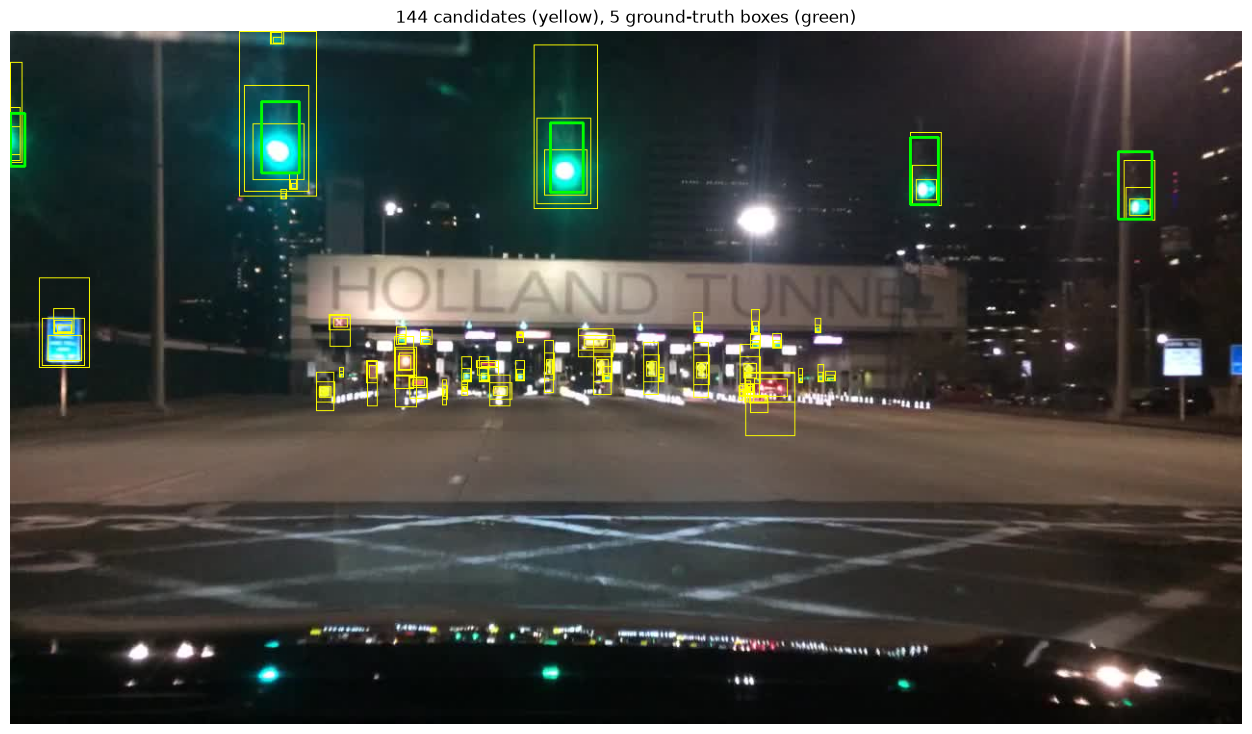

In [ ]:
# How far the box extends beyond the lamp: (left, right, up, down) in lamp widths / heights
BOX_TYPES = {
    "lamp": {"red": (0, 0, 0, 0), "yellow": (0, 0, 0, 0), "green": (0, 0, 0, 0)},
    "tight": {color: tuple(offsets.loc[color]) for color in offsets.index},
    "full": {"red": (0.25, 0.25, 0.3, 2.3), "yellow": (0.25, 0.25, 1.3, 1.3), "green": (0.25, 0.25, 2.3, 0.3)},
}

def light_candidates(img):
    # Every lamp proposes three boxes (one per box type)
    candidates = []
    for number, lamp in enumerate(find_lamps(img)):
        x, y, w, h = lamp["x"], lamp["y"], lamp["w"], lamp["h"]
        for box_type, table in BOX_TYPES.items():
            left, right, up, down = table[lamp["color"]]
            c = dict(lamp)   # copy of the lamp description
            c["x1"] = max(0, x - left * w)
            c["y1"] = max(0, y - up * h)
            c["x2"] = min(1280, x + w + right * w)
            c["y2"] = min(YMAX, y + h + down * h)
            c["lamp"] = number        # which lamp of the image proposed this box
            c["box_type"] = box_type
            candidates.append(c)
    return candidates

show_candidates("bdd100k_images_100k/100k/train/01bfe142-6e234db0.jpg", light_candidates, light_boxes)

In [ ]:
# Candidates from all images (about 1 min)
light_train = collect_candidates(train_images, light_candidates, light_boxes)
light_tune = collect_candidates(tune_images, light_candidates, light_boxes)
light_test = collect_candidates(test_images, light_candidates, light_boxes)

print("training candidates:", len(light_train), " of which hit a light:", light_train["is_object"].sum())
light_train.head()

training candidates: 226032  of which hit a light: 1922


,x,y,w,h,color,lamp_fill,same_around,brightness_around,lamp_saturation,lamp_brightness,x1,y1,x2,y2,lamp,box_type,image,is_object
0,1042,309,3,6,red,0.388889,0.023810,159.571429,93.166667,161.666667,1042.000000,309.000000,1045.000000,315.000000,0,lamp,bdd100k_images_100k/100k/train/115d9e12-16ebd2...,False
1,1042,309,3,6,red,0.388889,0.023810,159.571429,93.166667,161.666667,1041.141606,306.911289,1045.739834,317.325747,0,tight,bdd100k_images_100k/100k/train/115d9e12-16ebd2...,False
2,1042,309,3,6,red,0.388889,0.023810,159.571429,93.166667,161.666667,1041.250000,307.200000,1045.750000,328.800000,0,full,bdd100k_images_100k/100k/train/115d9e12-16ebd2...,False
3,1002,314,4,5,red,0.350000,0.019231,171.134615,92.700000,144.950000,1002.000000,314.000000,1006.000000,319.000000,1,lamp,bdd100k_images_100k/100k/train/115d9e12-16ebd2...,False
4,1002,314,4,5,red,0.350000,0.019231,171.134615,92.700000,144.950000,1000.855474,312.259407,1006.986445,320.938122,1,tight,bdd100k_images_100k/100k/train/115d9e12-16ebd2...,False


### Statystyki i uczenie przez zliczanie

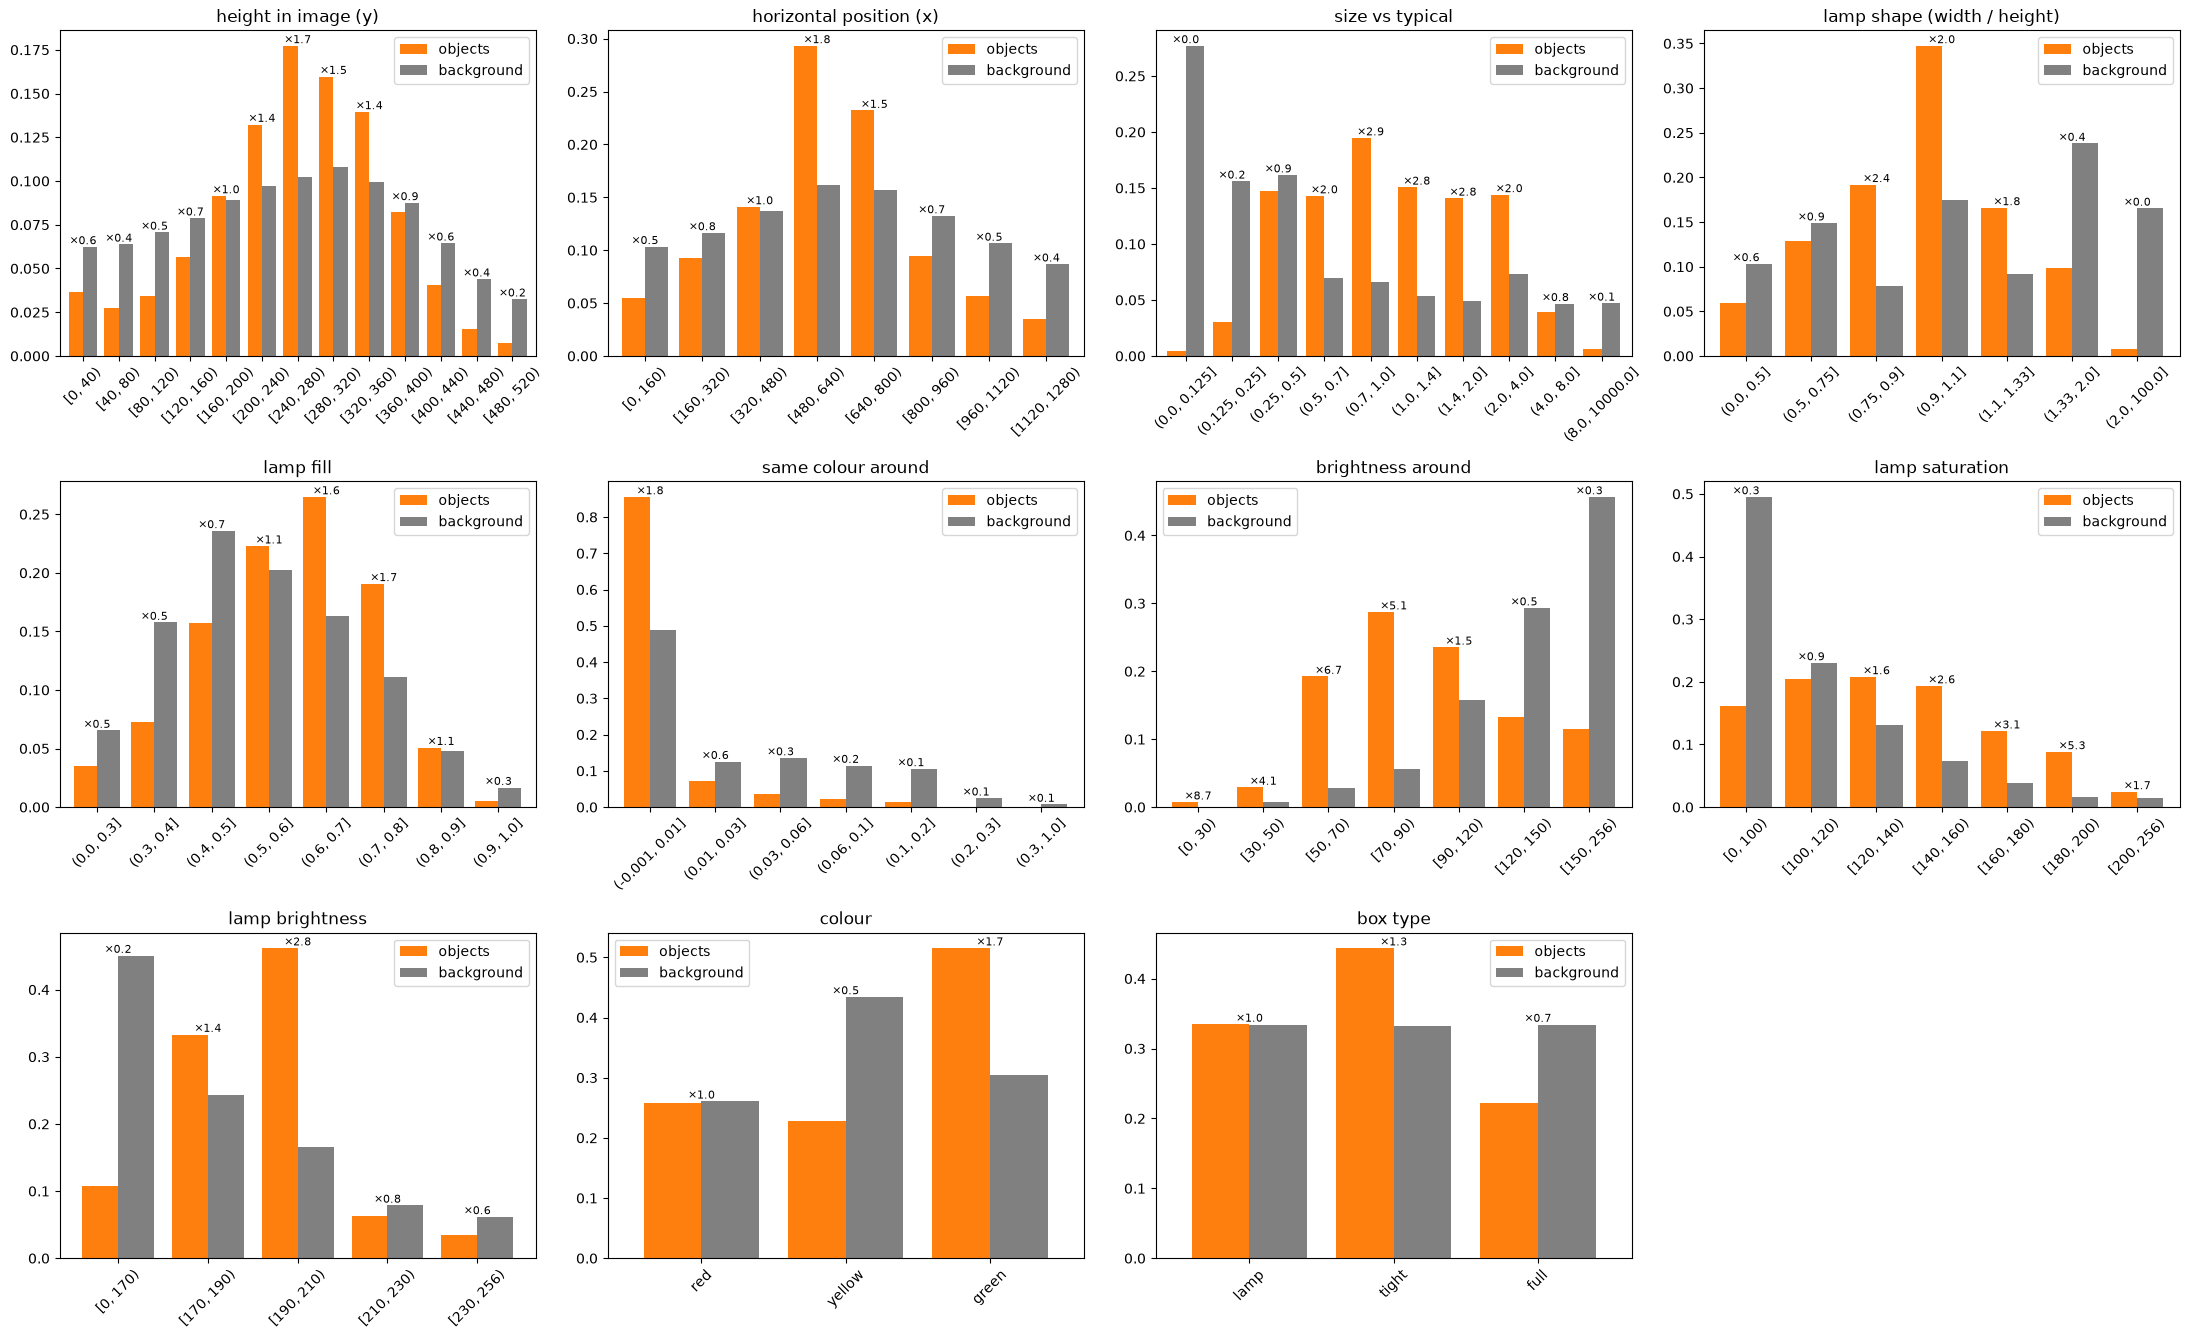

prior odds: 1 object per 117 background candidates


In [ ]:
light_area_map = typical_area_map("traffic light")

def light_statistics(cand):
    s = location_statistics(cand, light_area_map)   # position and size vs typical
    s["lamp shape (width / height)"] = pd.cut(cand["w"] / cand["h"], [0, 0.5, 0.75, 0.9, 1.1, 1.33, 2, 100])
    s["lamp fill"] = pd.cut(cand["lamp_fill"], [0, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1])
    s["same colour around"] = pd.cut(cand["same_around"], [0, 0.01, 0.03, 0.06, 0.1, 0.2, 0.3, 1], include_lowest=True)
    s["brightness around"] = pd.cut(cand["brightness_around"], [0, 30, 50, 70, 90, 120, 150, 256], right=False)
    s["lamp saturation"] = pd.cut(cand["lamp_saturation"], [0, 100, 120, 140, 160, 180, 200, 256], right=False)
    s["lamp brightness"] = pd.cut(cand["lamp_brightness"], [0, 170, 190, 210, 230, 256], right=False)
    s["colour"] = pd.Categorical(cand["color"], categories=["red", "yellow", "green"])
    s["box type"] = pd.Categorical(cand["box_type"], categories=list(BOX_TYPES))
    return s

light_train_stats = light_statistics(light_train)
light_model = train_model(light_train_stats, light_train["is_object"])

### Prawdopodobieństwo i wybór progu

Każda lampa zaproponowała trzy ramki, więc z każdej lampy zostawiamy tylko tę najbardziej prawdopodobną.

In [ ]:
def best_box_per_lamp(cand):
    # every lamp proposed three boxes - keep only the most probable one
    return cand.loc[cand.groupby(["image", "lamp"])["p"].idxmax()]

light_tune_stats = light_statistics(light_tune)
light_test_stats = light_statistics(light_test)
light_tune["p"] = probability(light_model, light_tune_stats)
light_test["p"] = probability(light_model, light_test_stats)

explain(light_model, light_tune, light_tune_stats, light_tune["p"].idxmax())   # the most probable candidate
explain(light_model, light_tune, light_tune_stats, light_tune["p"].idxmin())   # the least probable candidate

LIGHT_THRESHOLD = choose_threshold(best_box_per_lamp(light_tune), tune_images, light_boxes)
print("\nchosen threshold:", LIGHT_THRESHOLD)

candidate 6525: box (572, 296) - (586, 310), really an object: False
  prior odds                                      0.0086
  height in image (y)          [280, 320)       × 1.47
  horizontal position (x)      [480, 640)       × 1.82
  size vs typical              (1.0, 1.4]       × 2.81
  lamp shape (width / height)  (0.9, 1.1]       × 1.99
  lamp fill                    (0.7, 0.8]       × 1.72
  same colour around           (-0.001, 0.01]   × 1.76
  brightness around            [50, 70)         × 6.75
  lamp saturation              [180, 200)       × 5.32
  lamp brightness              [190, 210)       × 2.79
  colour                       green            × 1.69
  box type                     lamp             × 1.00
  probability: 0.985

candidate 44817: box (1245, 112) - (1257, 117), really an object: False
  prior odds                                      0.0086
  height in image (y)          [80, 120)        × 0.48
  horizontal position (x)      [1120, 1280)     × 0.40
  size v

 threshold  precision  recall    F1  accuracy
      0.02      0.082   0.221 0.120     0.064
      0.05      0.113   0.210 0.147     0.079
      0.10      0.135   0.190 0.158     0.086
      0.15      0.155   0.180 0.166     0.091
      0.20      0.167   0.166 0.167     0.091
      0.30      0.188   0.146 0.164     0.089
      0.40      0.219   0.134 0.166     0.091
      0.50      0.254   0.120 0.163     0.089
      0.60      0.312   0.113 0.166     0.090
      0.70      0.358   0.094 0.148     0.080
      0.80      0.465   0.080 0.137     0.073
      0.90      0.565   0.043 0.079     0.041

chosen threshold: 0.2


### Która statystyka ile daje?

In [ ]:
def light_f1_using(names):
    light_tune["p"] = probability(light_model, light_tune_stats, names)
    return best_f1(best_box_per_lamp(light_tune), tune_images, light_boxes)

contribution_table(light_f1_using, list(light_model["ratios"]))
light_tune["p"] = probability(light_model, light_tune_stats)   # restore the probability from all statistics

                          statistics    F1  change
                            all used 0.166   0.000
        without: height in image (y) 0.168   0.002
    without: horizontal position (x) 0.170   0.004
            without: size vs typical 0.125  -0.041
without: lamp shape (width / height) 0.160  -0.006
                  without: lamp fill 0.165  -0.001
         without: same colour around 0.168   0.002
          without: brightness around 0.162  -0.004
            without: lamp saturation 0.162  -0.004
            without: lamp brightness 0.160  -0.006
                     without: colour 0.160  -0.006
                   without: box type 0.159  -0.007
           only: height in image (y) 0.019  -0.147
       only: horizontal position (x) 0.023  -0.143
               only: size vs typical 0.033  -0.133
   only: lamp shape (width / height) 0.022  -0.144
                     only: lamp fill 0.009  -0.157
            only: same colour around 0.025  -0.140
             only: brightness a

### Test 2: sygnalizatory

Najpierw sama lokalizacja (precision / recall / F1 / accuracy przy IoU ≥ 0.5), potem kolor – oceniany tylko dla poprawnie zlokalizowanych świateł.
Model wykrywa wyłącznie zapalone lampy, więc nigdy nie przewiduje koloru „none” (unknown).

TEST 2 - traffic lights (500 images, threshold 0.2):
precision = 0.160  recall = 0.144  F1 = 0.152  accuracy = 0.082


recall ceiling (all candidates): 0.360



colour of the correctly located lights:
predicted colour  green  red  yellow
true colour                         
green               119    0       0
none                  3    1       0
red                   0   53       7
yellow                0    0       4

colour accuracy (lights with a known colour): 0.962


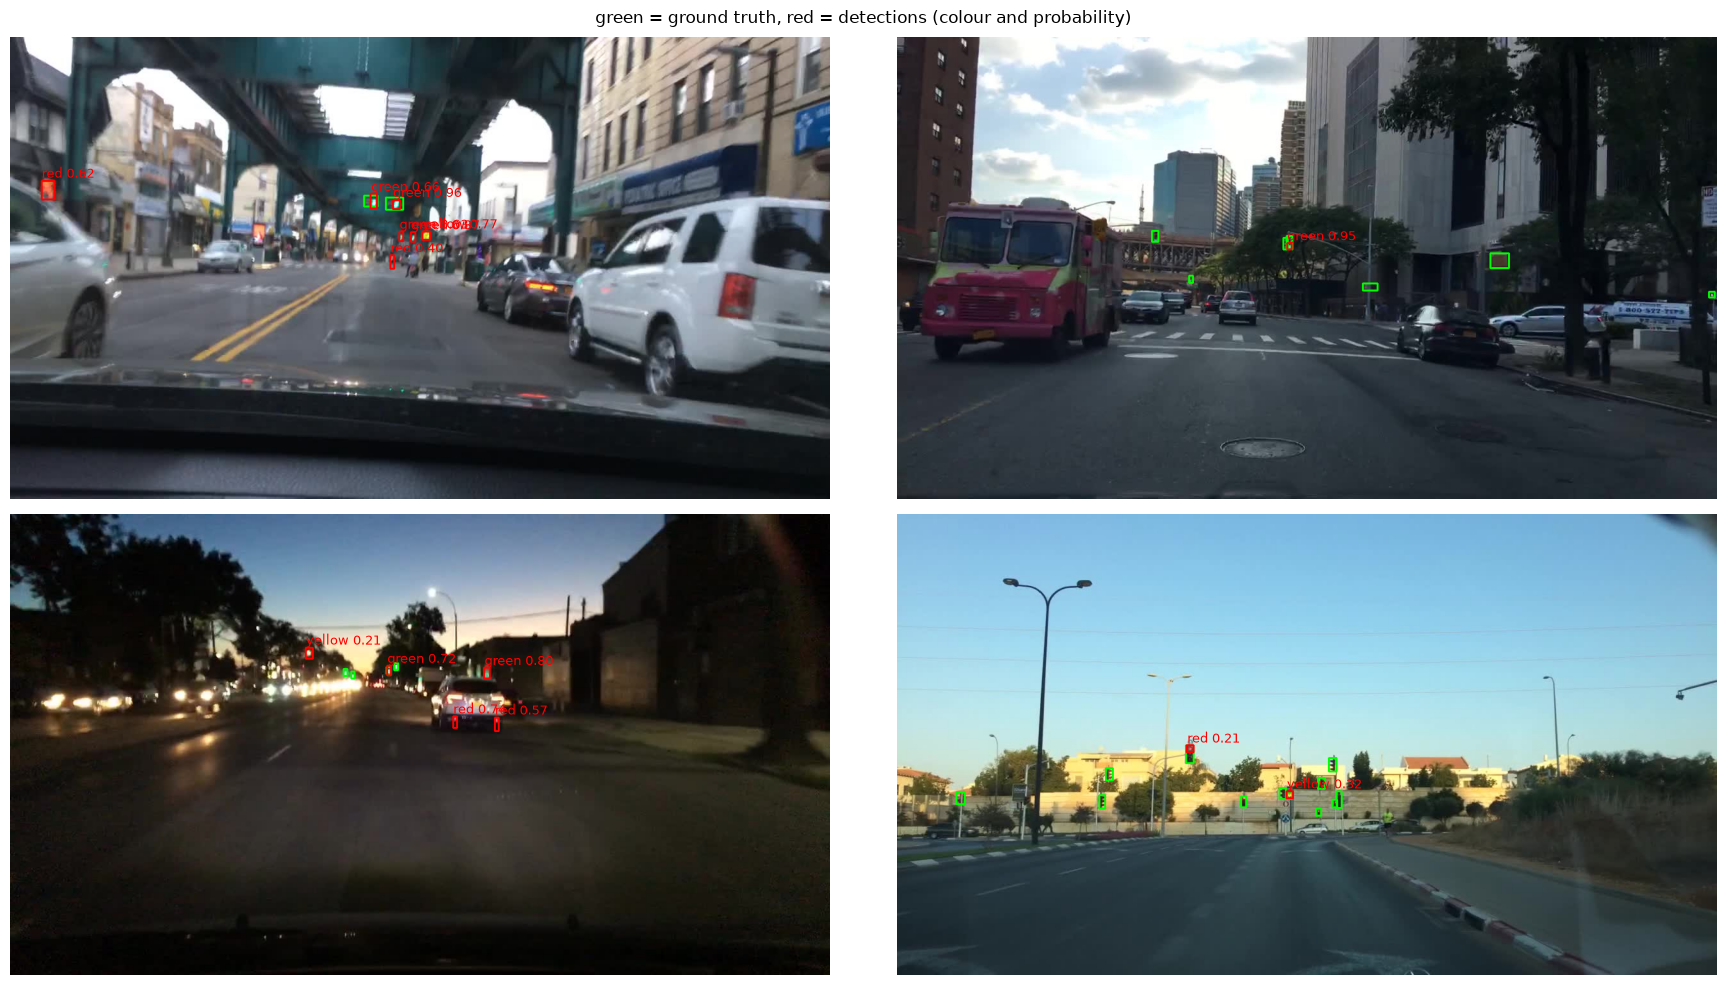

In [ ]:
light_detections = detect(best_box_per_lamp(light_test), LIGHT_THRESHOLD)
precision, recall, f1, accuracy = evaluate(light_detections, test_images, light_boxes)
print(f"TEST 2 - traffic lights ({len(test_images)} images, threshold {LIGHT_THRESHOLD}):")
print(f"precision = {precision:.3f}  recall = {recall:.3f}  F1 = {f1:.3f}  accuracy = {accuracy:.3f}")
print(f"recall ceiling (all candidates): {evaluate(light_test, test_images, light_boxes)[1]:.3f}")

# Colour of the correctly located lights: predicted colour = colour of the lamp
rows = []
for image, group in light_detections.groupby("image"):
    for i, j in match(group, light_boxes.get(image, [])).items():
        rows.append({"true colour": light_colors[image][j], "predicted colour": group.loc[i, "color"]})
colors = pd.DataFrame(rows)
print("\ncolour of the correctly located lights:")
print(pd.crosstab(colors["true colour"], colors["predicted colour"]))
known = colors[colors["true colour"] != "none"]
print(f"\ncolour accuracy (lights with a known colour): {(known['true colour'] == known['predicted colour']).mean():.3f}")

show_detections(light_detections, light_boxes)